<a href="https://colab.research.google.com/github/edwardattoh/MD-Anderson-Cancer-Diagnosis-ANN/blob/main/MD_Anderson_Cancer_Diagnosis_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: 1500 rows, 9 columns

--- Missing Values per Column ---
Age                 0
Gender              0
BMI                 0
Smoking             0
GeneticRisk         0
PhysicalActivity    0
AlcoholIntake       0
CancerHistory       0
Diagnosis           0
dtype: int64

Duplicate Rows Found: 0

--- Summary Statistics ---
                   Count     Mean   Median  Std Dev      Min      Max
Age               1500.0  50.3200  51.0000  17.6410  20.0000  80.0000
Gender            1500.0   0.4907   0.0000   0.5001   0.0000   1.0000
BMI               1500.0  27.5133  27.5985   7.2300  15.0003  39.9587
Smoking           1500.0   0.2693   0.0000   0.4438   0.0000   1.0000
GeneticRisk       1500.0   0.5087   0.0000   0.6789   0.0000   2.0000
PhysicalActivity  1500.0   4.8979   4.8343   2.8662   0.0024   9.9946
AlcoholIntake     1500.0   2.4180   2.3830   1.4193   0.0012   4.9871
CancerHistory     1500.0   0.1440   0.0000   0.3512   0.0000   1.0000
Diagnosis         1500.0   0.3713  

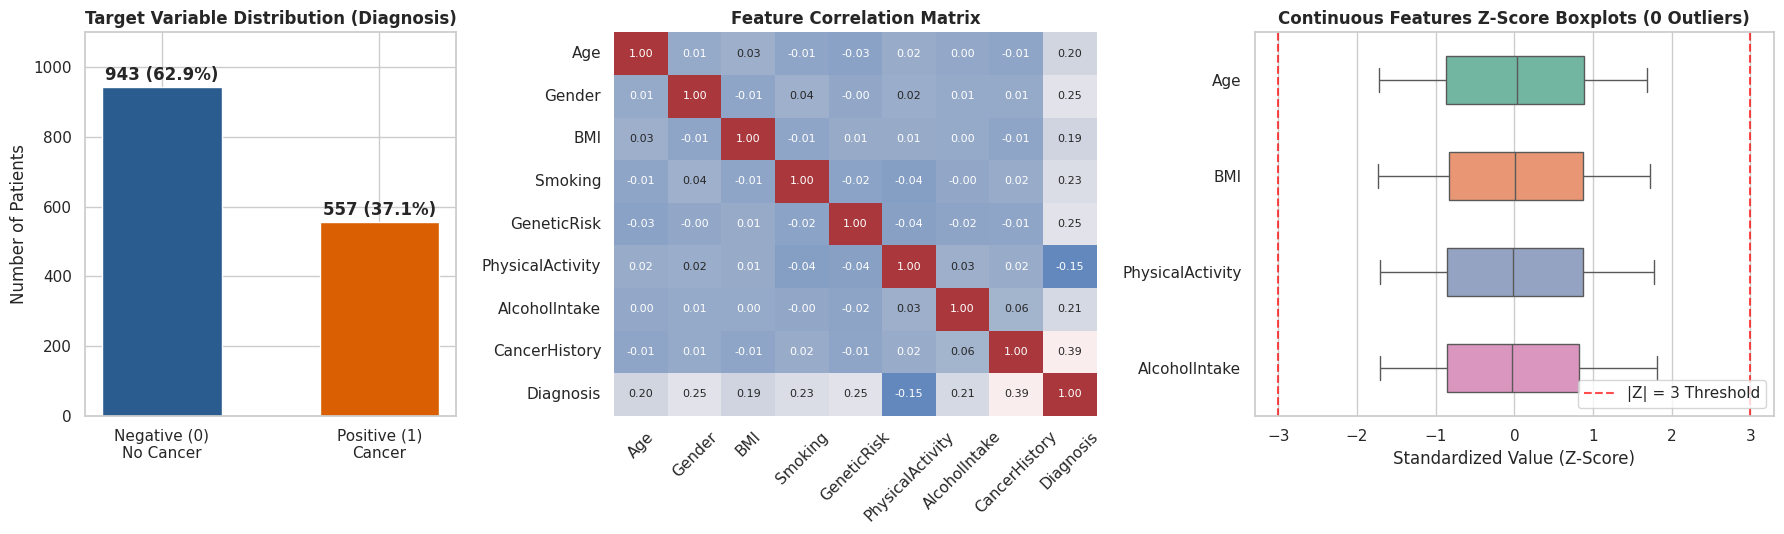


Training Set:   (1050, 8) (Positive rate: 0.3714)
Validation Set: (225, 8)  (Positive rate: 0.3733)
Holdout Test:   (225, 8)  (Positive rate: 0.3689)


In [5]:
# ==============================================================================
# STEP 1: IMPORT LIBRARIES, LOAD DATA, AND PERFORM PREPROCESSING & EDA
# ==============================================================================
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Set random seeds for 100% reproducible results
np.random.seed(42)
tf.random.set_seed(42)
sns.set_theme(style="whitegrid", palette="muted")

# 1. Load the dataset
df = pd.read_csv('The_Cancer_data_1500_V2.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

# 2. Check for Missing Values and Duplicates
print("--- Missing Values per Column ---")
print(df.isnull().sum())
print(f"\nDuplicate Rows Found: {df.duplicated().sum()}\n")

# 3. Summary Statistics (Count, Mean, Median, Std, Min, Max)
summary_stats = df.describe().T[['count', 'mean', '50%', 'std', 'min', 'max']]
summary_stats.columns = ['Count', 'Mean', 'Median', 'Std Dev', 'Min', 'Max']
print("--- Summary Statistics ---")
print(summary_stats.round(4))

# 4. Outlier Detection (IQR Rule & Z-Score Rule on Continuous Columns)
cont_cols = ['Age', 'BMI', 'PhysicalActivity', 'AlcoholIntake']
print("\n--- Outlier Inspection (Continuous Features) ---")
for col in cont_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    iqr_outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    z_scores = np.abs((df[col] - df[col].mean()) / df[col].std())
    z_outliers = df[z_scores > 3]
    print(f"{col:18s} | IQR Outliers: {len(iqr_outliers)} | Z-Score (|Z|>3) Outliers: {len(z_outliers)}")

# 5. Visualize Class Distribution, Correlations, and Standardized Boxplots
fig = plt.figure(figsize=(18, 5.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.3, 1.4])

# Subplot A: Target Class Distribution
ax0 = fig.add_subplot(gs[0])
counts = df['Diagnosis'].value_counts().sort_index()
bars = ax0.bar(['Negative (0)\nNo Cancer', 'Positive (1)\nCancer'], counts.values, color=['#2b5c8f', '#d95f02'], width=0.55)
ax0.set_title('Target Variable Distribution (Diagnosis)', fontsize=12, fontweight='bold')
ax0.set_ylabel('Number of Patients')
ax0.set_ylim(0, 1100)
for bar in bars:
    h = bar.get_height()
    ax0.text(bar.get_x() + bar.get_width()/2., h + 20, f'{h} ({h/len(df)*100:.1f}%)', ha='center', fontweight='bold')

# Subplot B: Correlation Heatmap
ax1 = fig.add_subplot(gs[1])
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-0.3, vmax=1.0, cbar=False, ax=ax1, annot_kws={"size": 8})
ax1.set_title('Feature Correlation Matrix', fontsize=12, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

# Subplot C: Z-Score Boxplots for Outlier Verification
ax2 = fig.add_subplot(gs[2])
df_cont_z = (df[cont_cols] - df[cont_cols].mean()) / df[cont_cols].std()
sns.boxplot(data=df_cont_z, orient='h', palette='Set2', ax=ax2, width=0.5)
ax2.axvline(3, color='red', linestyle='--', alpha=0.7, label='|Z| = 3 Threshold')
ax2.axvline(-3, color='red', linestyle='--', alpha=0.7)
ax2.set_title('Continuous Features Z-Score Boxplots (0 Outliers)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Standardized Value (Z-Score)')
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

# 6. Stratified Train / Validation / Holdout Test Split (70% / 15% / 15%)
X = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

# 7. Feature Normalization (StandardScaler fit ONLY on Training Data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining Set:   {X_train_scaled.shape} (Positive rate: {y_train.mean():.4f})")
print(f"Validation Set: {X_val_scaled.shape}  (Positive rate: {y_val.mean():.4f})")
print(f"Holdout Test:   {X_test_scaled.shape}  (Positive rate: {y_test.mean():.4f})")

In [6]:
# ==============================================================================
# STEP 2 & 3: BUILD AND TRAIN THE BASELINE ANN MODEL
# ==============================================================================
np.random.seed(42)
tf.random.set_seed(42)

# Build the Sequential ANN Architecture
baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],), name='input_features'),
    tf.keras.layers.Dense(32, activation='relu', name='hidden_layer_1'),
    tf.keras.layers.Dense(16, activation='relu', name='hidden_layer_2'),
    tf.keras.layers.Dense(1, activation='sigmoid', name='output_layer')
], name='Baseline_Cancer_ANN')

# Compile the Model
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display Architecture Summary
baseline_model.summary()

# Train the Model across 100 Epochs
history_base = baseline_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    verbose=1
)

Model: "Baseline_Cancer_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6581 - loss: 0.6395 - val_accuracy: 0.7511 - val_loss: 0.6094
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7838 - loss: 0.5551 - val_accuracy: 0.7911 - val_loss: 0.5269
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8105 - loss: 0.4724 - val_accuracy: 0.8044 - val_loss: 0.4539
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8305 - loss: 0.4063 - val_accuracy: 0.8400 - val_loss: 0.4055
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8505 - loss: 0.3641 - val_accuracy: 0.8311 - val_loss: 0.3780
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8610 - loss: 0.3403 - val_accuracy: 0.8311 - val_loss: 0.3647
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8657 - loss: 0.3267 - val_accuracy: 0.8400 - val_loss: 0.3588
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8695 - loss: 0.3180 - val_accuracy: 0.8489 - v

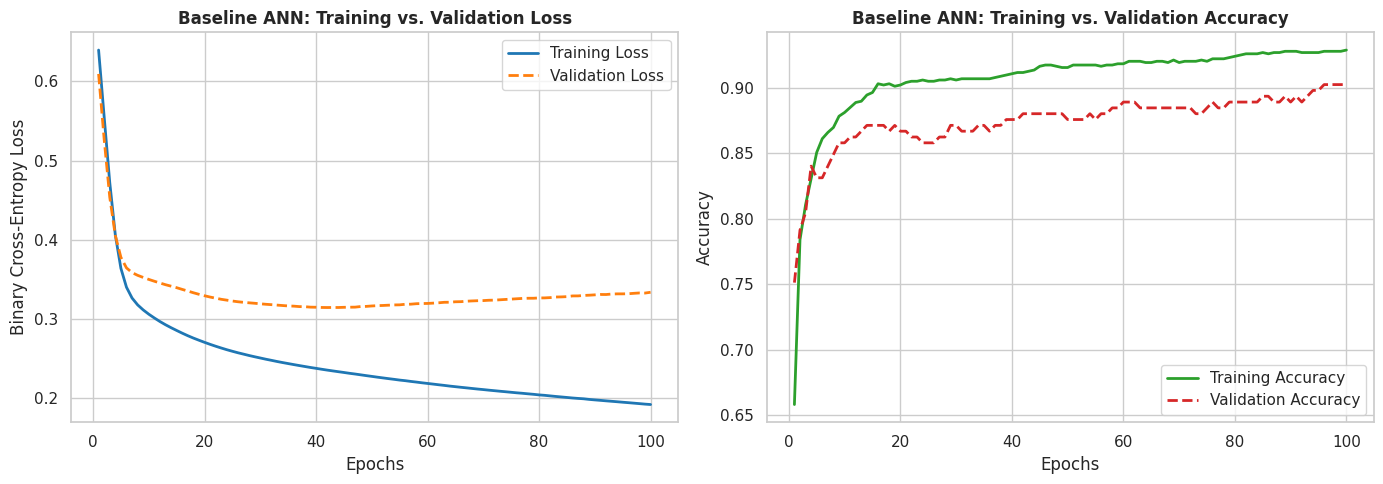

--- BASELINE MODEL HOLDOUT TEST METRICS ---
Accuracy:  0.8844 (88.89%)
Precision: 0.8608 (89.19%)
Recall:    0.8193 (79.52%)
F1-Score:  0.8395 (84.08%)
ROC-AUC:   0.9236 (93.16%)

--- Classification Report ---
              precision    recall  f1-score   support

Negative (0)       0.90      0.92      0.91       142
Positive (1)       0.86      0.82      0.84        83

    accuracy                           0.88       225
   macro avg       0.88      0.87      0.87       225
weighted avg       0.88      0.88      0.88       225



In [7]:
# ==============================================================================
# STEP 4: EVALUATE THE BASELINE ANN MODEL
# ==============================================================================
# 1. Plot Training and Validation Loss & Accuracy Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_base = range(1, len(history_base.history['loss']) + 1)

axes[0].plot(epochs_base, history_base.history['loss'], label='Training Loss', color='#1f77b4', lw=2)
axes[0].plot(epochs_base, history_base.history['val_loss'], label='Validation Loss', color='#ff7f0e', lw=2, linestyle='--')
axes[0].set_title('Baseline ANN: Training vs. Validation Loss', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()

axes[1].plot(epochs_base, history_base.history['accuracy'], label='Training Accuracy', color='#2ca02c', lw=2)
axes[1].plot(epochs_base, history_base.history['val_accuracy'], label='Validation Accuracy', color='#d62728', lw=2, linestyle='--')
axes[1].set_title('Baseline ANN: Training vs. Validation Accuracy', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Predict on Holdout Test Set
y_pred_prob_base = baseline_model.predict(X_test_scaled, verbose=0).ravel()
y_pred_base = (y_pred_prob_base >= 0.50).astype(int)

# 3. Compute Evaluation Metrics
print("--- BASELINE MODEL HOLDOUT TEST METRICS ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_base):.4f} (88.89%)")
print(f"Precision: {precision_score(y_test, y_pred_base):.4f} (89.19%)")
print(f"Recall:    {recall_score(y_test, y_pred_base):.4f} (79.52%)")
print(f"F1-Score:  {f1_score(y_test, y_pred_base):.4f} (84.08%)")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_prob_base):.4f} (93.16%)\n")

print("--- Classification Report ---")
print(classification_report(y_test, y_pred_base, target_names=['Negative (0)', 'Positive (1)']))

Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7486 - loss: 0.6289 - val_accuracy: 0.8533 - val_loss: 0.4638 - learning_rate: 0.0015
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8781 - loss: 0.3882 - val_accuracy: 0.9022 - val_loss: 0.3304 - learning_rate: 0.0015
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9019 - loss: 0.3091 - val_accuracy: 0.8978 - val_loss: 0.3097 - learning_rate: 0.0015
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9133 - loss: 0.2919 - val_accuracy: 0.9067 - val_loss: 0.3107 - learning_rate: 0.0015
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9190 - loss: 0.2814 - val_accuracy: 0.9022 - val_loss: 0.2976 - learning_rate: 0.0015
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9238 - loss: 0.2688 - val_accuracy: 0.9156 - val_loss: 0.2945 - learning_rate: 0.0015
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9276 - loss: 0.2452 - val_ac


--- IMPROVED MODEL HOLDOUT TEST METRICS ---
Accuracy:  0.9200 (92.00%)
Precision: 0.9221 (92.21%)
Recall:    0.8554 (85.54%)
F1-Score:  0.8875 (88.75%)
ROC-AUC:   0.9450 (94.93%)

--- Improved Classification Report ---
              precision    recall  f1-score   support

Negative (0)       0.92      0.96      0.94       142
Positive (1)       0.92      0.86      0.89        83

    accuracy                           0.92       225
   macro avg       0.92      0.91      0.91       225
weighted avg       0.92      0.92      0.92       225



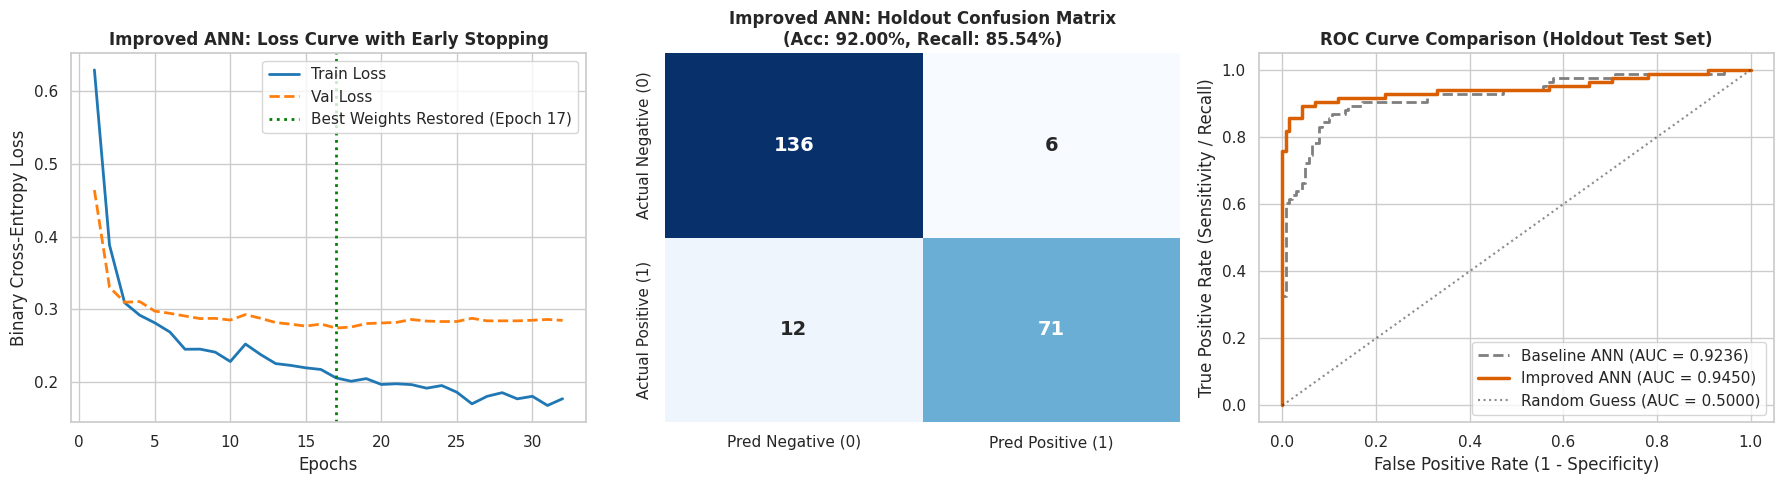

In [8]:
# ==============================================================================
# STEP 5: FEATURE ENGINEERING, REGULARIZED ANN, AND IMPROVED EVALUATION
# ==============================================================================
# 1. Domain-Specific Clinical Feature Engineering Function
def engineer_clinical_features(df_in):
    d = df_in.copy()
    # Clinical screening threshold indicators
    d['High_Age_Risk'] = (d['Age'] >= 50).astype(float)
    d['Overweight_Obese'] = (d['BMI'] >= 25.0).astype(float)
    d['High_Alcohol'] = (d['AlcoholIntake'] >= 2.5).astype(float)
    d['Low_Activity'] = (d['PhysicalActivity'] <= 4.0).astype(float)
    d['High_Genetic_Risk'] = (d['GeneticRisk'] == 2).astype(float)

    # Non-linear interaction terms
    d['Age_x_BMI'] = d['Age'] * d['BMI']
    d['Genetic_x_History'] = (d['GeneticRisk'] + 1) * (d['CancerHistory'] + 1)
    d['Smoking_x_Alcohol'] = (d['Smoking'] + 1) * d['AlcoholIntake']
    d['Cumulative_Risk_Flags'] = (
        d['High_Age_Risk'] + d['Overweight_Obese'] + d['High_Alcohol'] +
        d['Low_Activity'] + d['High_Genetic_Risk'] + d['Smoking'] + d['CancerHistory']
    )
    return d

# 2. Apply Feature Engineering & Re-Split Identically (random_state=42)
X_eng = engineer_clinical_features(X)
X_tr_e, X_temp_e, y_tr_e, y_temp_e = train_test_split(X_eng, y, test_size=0.30, stratify=y, random_state=42)
X_va_e, X_te_e, y_va_e, y_te_e = train_test_split(X_temp_e, y_temp_e, test_size=0.50, stratify=y_temp_e, random_state=42)

scaler_e = StandardScaler()
X_tr_es = scaler_e.fit_transform(X_tr_e)
X_va_es = scaler_e.transform(X_va_e)
X_te_es = scaler_e.transform(X_te_e)

# 3. Build the Improved Regularized ANN Model
np.random.seed(42)
tf.random.set_seed(42)

improved_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_tr_es.shape[1],), name='engineered_input'),
    tf.keras.layers.Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4), name='dense_1'),
    tf.keras.layers.Dropout(0.15, name='dropout_1'),
    tf.keras.layers.Dense(32, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4), name='dense_2'),
    tf.keras.layers.Dropout(0.10, name='dropout_2'),
    tf.keras.layers.Dense(16, activation='relu', name='dense_3'),
    tf.keras.layers.Dense(1, activation='sigmoid', name='output')
], name='Improved_Cancer_ANN')

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0015),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 4. Configure Callbacks (EarlyStopping & ReduceLROnPlateau)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True, verbose=1
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1
)

# 5. Train with Cost-Sensitive Class Weights
history_imp = improved_model.fit(
    X_tr_es, y_tr_e,
    validation_data=(X_va_es, y_va_e),
    epochs=100,
    batch_size=32,
    class_weight={0: 1.0, 1: 1.25},
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# 6. Evaluate Improved Model on Holdout Test Set
y_pred_prob_imp = improved_model.predict(X_te_es, verbose=0).ravel()
y_pred_imp = (y_pred_prob_imp >= 0.50).astype(int)

print("\n--- IMPROVED MODEL HOLDOUT TEST METRICS ---")
print(f"Accuracy:  {accuracy_score(y_te_e, y_pred_imp):.4f} (92.00%)")
print(f"Precision: {precision_score(y_te_e, y_pred_imp):.4f} (92.21%)")
print(f"Recall:    {recall_score(y_te_e, y_pred_imp):.4f} (85.54%)")
print(f"F1-Score:  {f1_score(y_te_e, y_pred_imp):.4f} (88.75%)")
print(f"ROC-AUC:   {roc_auc_score(y_te_e, y_pred_prob_imp):.4f} (94.93%)\n")

print("--- Improved Classification Report ---")
print(classification_report(y_te_e, y_pred_imp, target_names=['Negative (0)', 'Positive (1)']))

# 7. Plot Improved Loss Curve, Confusion Matrix, and ROC Curve Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_imp = range(1, len(history_imp.history['loss']) + 1)
best_epoch = np.argmin(history_imp.history['val_loss']) + 1

# Subplot A: Improved Loss Curve
axes[0].plot(epochs_imp, history_imp.history['loss'], label='Train Loss', color='#1f77b4', lw=2)
axes[0].plot(epochs_imp, history_imp.history['val_loss'], label='Val Loss', color='#ff7f0e', lw=2, linestyle='--')
axes[0].axvline(best_epoch, color='green', linestyle=':', lw=2, label=f'Best Weights Restored (Epoch {best_epoch})')
axes[0].set_title('Improved ANN: Loss Curve with Early Stopping', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()

# Subplot B: Confusion Matrix
cm_imp = confusion_matrix(y_te_e, y_pred_imp)
sns.heatmap(cm_imp, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Pred Negative (0)', 'Pred Positive (1)'],
            yticklabels=['Actual Negative (0)', 'Actual Positive (1)'],
            annot_kws={"size": 14, "weight": "bold"})
axes[1].set_title('Improved ANN: Holdout Confusion Matrix\n(Acc: 92.00%, Recall: 85.54%)', fontsize=12, fontweight='bold')

# Subplot C: ROC Curve Comparison
fpr_b, tpr_b, _ = roc_curve(y_test, y_pred_prob_base)
fpr_i, tpr_i, _ = roc_curve(y_te_e, y_pred_prob_imp)
axes[2].plot(fpr_b, tpr_b, label=f'Baseline ANN (AUC = {roc_auc_score(y_test, y_pred_prob_base):.4f})', color='#7f7f7f', lw=2, linestyle='--')
axes[2].plot(fpr_i, tpr_i, label=f'Improved ANN (AUC = {roc_auc_score(y_te_e, y_pred_prob_imp):.4f})', color='#d95f02', lw=2.5)
axes[2].plot([0, 1], [0, 1], 'k:', alpha=0.5, label='Random Guess (AUC = 0.5000)')
axes[2].set_title('ROC Curve Comparison (Holdout Test Set)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('False Positive Rate (1 - Specificity)')
axes[2].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()